# Comparar manifestos de urnas

Os HTMLs `path1u13`, `path1u15`, `path1u20` e `path1u22` descrevem os modelos de urna 2013, 2015, 2020 e 2022. A comparação é entre **caminhos e hashes publicados**, não uma auditoria dos binários nem uma comparação de votos. As linhas `UF = ...` são seções e `HASH GERAL UF = ...` são resumos agregados: nenhuma delas é um arquivo comum.

As figuras PNG abaixo já fazem parte do `.ipynb` e são mantidas quando ele é reexecutado/salvo.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt

# Funciona tanto no diretório do notebook (test/) quanto na raiz do projeto.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "extracted").is_dir() and (p / "test" / "manifestos.py").is_file()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError("Abra este notebook na raiz do repositório ou em test/.")
sys.path.insert(0, str(RAIZ / "test"))
from manifestos import load_manifests, is_sha512_base64
from notebook_utils import show_table

manifestos = load_manifests(RAIZ)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print(f"Fonte: extracted/ — {len(manifestos)} manifestos HTML")
urnas = sorted((m for m in manifestos if m.family == "urnas"), key=lambda m: m.source.parent.name)
print("Modelos:", ", ".join(m.subtitle for m in urnas))

Fonte: extracted/ — 32 manifestos HTML
Modelos: Urna 2013 - 02/09/2026, Urna 2015 - 02/09/2026, Urna 2020 - 02/09/2026, Urna 2022 - 02/09/2026


## Arquivos-base e linhas por UF
Há entradas específicas de hardware na seção `ARQUIVOS BASE` e entradas por UF em cada modelo. O gráfico não conta os resumos agregados.

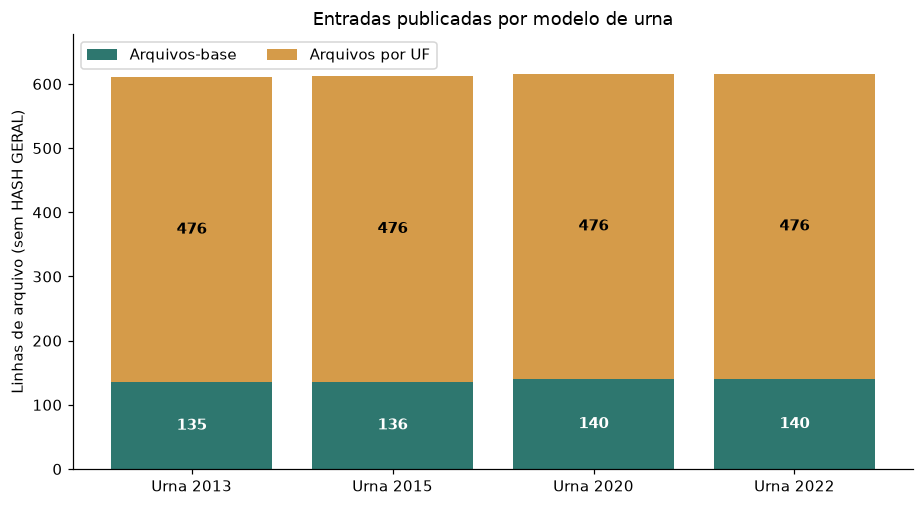

In [2]:
rotulos = [m.subtitle.rsplit(" - ", 1)[0] for m in urnas]
base = [sum(e.kind == "file" and e.section == "ARQUIVOS BASE" for e in m.entries)
        for m in urnas]
por_uf = [sum(e.kind == "file" and e.section.startswith("UF = ") for e in m.entries)
          for m in urnas]
fig, ax = plt.subplots(figsize=(8.5, 4.7))
ax.bar(rotulos, base, color="#2e776f", label="Arquivos-base")
ax.bar(rotulos, por_uf, bottom=base, color="#d59b49", label="Arquivos por UF")
for i, (b, u) in enumerate(zip(base, por_uf)):
    ax.text(i, b / 2, str(b), ha="center", va="center", color="white", fontweight="bold")
    ax.text(i, b + u / 2, str(u), ha="center", va="center", fontweight="bold")
ax.set_ylabel("Linhas de arquivo (sem HASH GERAL)")
ax.set_title("Entradas publicadas por modelo de urna")
ax.legend(loc="upper left", ncol=2)
ax.set_ylim(0, max(b + u for b, u in zip(base, por_uf)) * 1.1)
fig.tight_layout()
plt.show()

## Caminhos de arquivos-base entre modelos
Um caminho presente em vários modelos pode ter hash igual ou diferente. Um caminho exclusivo de um modelo não é um arquivo ausente: em geral, os nomes são específicos daquele hardware.

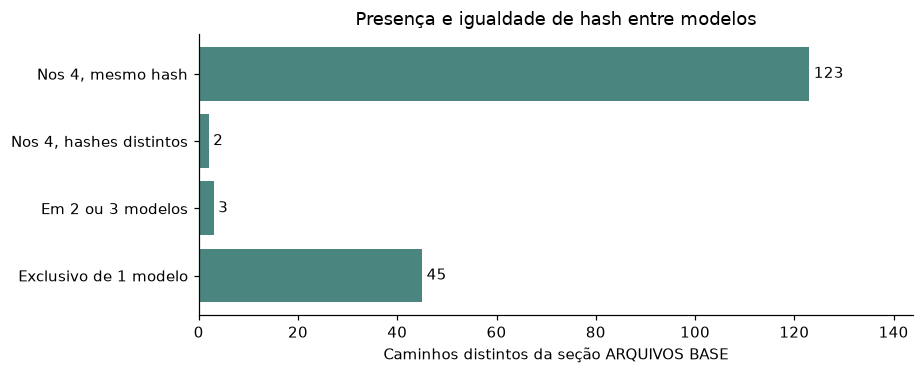

Caminho comum com hashes diferentes,Modelo,SHA-512 (Base64)
/uenux/lib/avusrlibue.vst,path1u13,4bhqFYSlk9pZkHfPv8YAzjcIU953ZV+NnMHEB4UGhjmm7okAcnkxVeK3PuU2fsDrgGD9TmsNntAGsWQ9ZbB3Tw==
/uenux/lib/avusrlibue.vst,path1u15,XQIkFMyYsCSnEui8yNmZhuhpLCvh+NY6J0ggEEAGZzMbDC4c8lwKE+qjgXvwEOx2DG8YIDhBLtDAKWz0Hw5keg==
/uenux/lib/avusrlibue.vst,path1u20,QM0yuAP9h1PDoDPMF5WFS36086O7bhqVK5udPE6MgZAkk0UjnMQItBVKmATURIeyYVXEDf+8pBan0Rx7ff6ueA==
/uenux/lib/avusrlibue.vst,path1u22,LUuM0WiMK0nknGAUgTGP8l1g6ENQzxTfNJ8Q5BnWd7lfAKBe2pcN671KPvEZOF4F0HQpcT8G1VYD0saKJyYO2g==
/uenux/lib/libapihwilue.so,path1u13,crSJj9vH4uTXI9K/ytT6Bexl3CrGkW9fhi5rwx0Npx/zxuF/x/sFHanAeeC1s0K0lVa0sI3cun3Ez0o0/MyI2g==
/uenux/lib/libapihwilue.so,path1u15,IveQwkSIQitiTHjnM/yoRDZuzmcNaU0PCpihSh3fCHaV2hQjOCKRYw1PtmaRS2jUmCVK+86vwtpIg9ukntEagw==
/uenux/lib/libapihwilue.so,path1u20,Ms/LYi65L4IXCCyx5X7O95yRfVjISXh4BF6IMPcPPZkAW4411ADniCn5ZUgPI7w9+ycG7EEHUgmirHVE/bZpxQ==
/uenux/lib/libapihwilue.so,path1u22,c7MRWu6GedNDpsQtej7QMsKqzkt2wNSAiCK33pLQpxhyiKXd8WiVIYiZVG8BLi6D9XgzOUtLl/gGU0aDDC+ctQ==


In [3]:
from collections import defaultdict

por_caminho = defaultdict(dict)
for m in urnas:
    for e in m.entries:
        if e.kind == "file" and e.section == "ARQUIVOS BASE":
            por_caminho[e.path][m.source.parent.name] = e.digest

classes = {
    "Nos 4, mesmo hash": sum(len(v) == 4 and len(set(v.values())) == 1
                            for v in por_caminho.values()),
    "Nos 4, hashes distintos": sum(len(v) == 4 and len(set(v.values())) > 1
                                 for v in por_caminho.values()),
    "Em 2 ou 3 modelos": sum(1 < len(v) < 4 for v in por_caminho.values()),
    "Exclusivo de 1 modelo": sum(len(v) == 1 for v in por_caminho.values()),
}
fig, ax = plt.subplots(figsize=(8.5, 3.5))
barras = ax.barh(list(classes), list(classes.values()), color="#4a8580")
ax.invert_yaxis()
ax.bar_label(barras, padding=3)
ax.set_xlim(0, max(classes.values()) * 1.17)
ax.set_xlabel("Caminhos distintos da seção ARQUIVOS BASE")
ax.set_title("Presença e igualdade de hash entre modelos")
fig.tight_layout()
plt.show()

variantes = [p for p, hashes in por_caminho.items()
             if len(hashes) == len(urnas) and len(set(hashes.values())) > 1]
show_table(
    ["Caminho comum com hashes diferentes", "Modelo", "SHA-512 (Base64)"],
    ((p, modelo, digest) for p in variantes for modelo, digest in por_caminho[p].items()),
)

## Explorar uma UF
Troque `UF`, `MODELO` ou `BUSCA_ARQUIVO` e execute as duas células. A tabela de **hashes gerais publicados** é mantida separada das entradas de arquivo. Mesmo que as entradas da UF coincidam entre modelos, o hash geral não precisa coincidir: não inferimos sua composição a partir deste HTML.

In [4]:
UF = "SP"             # AC, SP, ... ou ZZ (conforme o manifesto)
MODELO = "path1u20"   # path1u13 | path1u15 | path1u20 | path1u22
BUSCA_ARQUIVO = "tse.ber.pub"  # deixe vazio para listar todas as entradas da UF

In [5]:
secao = f"UF = {UF.strip().upper()}"
modelo = next((m for m in urnas if m.source.parent.name == MODELO), None)
if modelo is None:
    raise ValueError(f"Modelo não encontrado: {MODELO!r}")
arquivos = [e for e in modelo.entries if e.kind == "file" and e.section == secao]
if not arquivos:
    raise ValueError(f"Seção não encontrada: {secao!r}")

resumos = [
    (m.subtitle.rsplit(" - ", 1)[0], e.digest)
    for m in urnas for e in m.entries
    if e.kind == "aggregate" and e.path == f"HASH GERAL {secao}"
]
print(f"{len(arquivos)} arquivos listados para {secao} em {MODELO}.")
show_table(["Modelo", "HASH GERAL publicado (não é um arquivo)"], resumos)

selecionados = [e for e in arquivos if BUSCA_ARQUIVO.casefold() in e.path.casefold()]
print(f"{len(selecionados)} entradas de arquivo correspondentes a {BUSCA_ARQUIVO!r}.")
show_table(["Caminho", "SHA-512 (Base64)"],
           ((e.path, e.digest) for e in selecionados[:30]))
if len(selecionados) > 30:
    print("Exibindo apenas as primeiras 30 linhas; refine BUSCA_ARQUIVO.")

17 arquivos listados para UF = SP em path1u20.


Modelo,HASH GERAL publicado (não é um arquivo)
Urna 2013,TnKL7BBjA4UwMVLiFLRg97Ie6wgxafKxaAOxIdC5PbpQ/Por6fgExwQqXxwCf7pCzqLGey3Da7X0/ckHcQ5gdA==
Urna 2015,WeI4FIpAVDsDmKRPTGXGH2xiPrZI3N8gHkLIF09Y093qA6WUpSbv//jqD/8zoyVle57VwHvOpyAEoDl4FLY3/Q==
Urna 2020,axiRHK3R7iqjsJEDqcq6j2c5Bc0r0KHunohimles1J5N6NZLOcyk2/CiXyDcyzPGNLxxapBSnNSxpiBQuQSWIg==
Urna 2022,JBr0P+YBiTsPnWhUl/OHF05VBLIqTI+ABRH3CST7zHoaoZWemo0Hl18Nzx2F8rdZQGEtyYAfL0XFKSR4oV0WFA==


1 entradas de arquivo correspondentes a 'tse.ber.pub'.


Caminho,SHA-512 (Base64)
SP - /dsk/fi/estatico/chave/tse.ber.pub,IrnbQrrNQ8dRBu2zmBFdBAkUTdIUGjGBQ1CKX/y0Lw0iY+4MMSarP1Fo21NX3fUpzMQ0ErQYHxxFVc3++W1SpA==
